## 0. 환경 설정 ##

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib.font_manager as fm

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

train = pd.read_csv('/content/train.csv')
test = pd.read_csv('/content/test.csv')
trade = pd.read_csv('/content/international_trade.csv')
submission = pd.read_csv('/content/sample_submission.csv')


In [ ]:
!apt-get -qq install fonts-nanum

In [ ]:
def set_font():
  # 나눔 폰트 경로를 직접 검색하여 폰트 매니저에 등록
  for font_path in fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum']):
    fm.fontManager.addfont(font_path)

  candidates = ['NanumGothic', 'Malgun Gothic', 'AppleGothic', 'Noto Sans CJK KR', 'Noto Sans KR']
  installed = {f.name for f in fm.fontManager.ttflist}
  for name in candidates:
    if name in installed:
      plt.rc('font', family=name)
      plt.rc('axes', unicode_minus=False)
      return name
  print('폰트를 찾지 못함')
  return None

print('사용 폰트:', set_font())
sns.set_style('whitegrid')
plt.rc('font', family=plt.rcParams['font.family'])

item_name = {'TG': '감귤', 'BC': '브로콜리', 'RD': '무', 'CR': '당근', 'CB': '양배추'}
items = {'TG', 'BC', 'RD', 'CR', 'CB'}

사용 폰트: NanumGothic


In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import shutil

shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)

fm._rebuild() if hasattr(fm, '_rebuild') else None

for font_path in fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum']):
    fm.fontManager.addfont(font_path)

plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

print("설정된 폰트:", plt.rcParams['font.family'])

설정된 폰트: ['NanumGothic']


### 폰트 반영 테스트
위 셀을 실행한 후 아래 테스트 코드를 실행하여 한글이 올바르게 나오는지 확인해 보세요. (만약 이 방법으로도 깨진다면 상단 메뉴에서 `런타임` -> `런타임 다시 시작`을 누르신 뒤 처음부터 코드를 순서대로 다시 실행해 주시면 정상 작동합니다.)

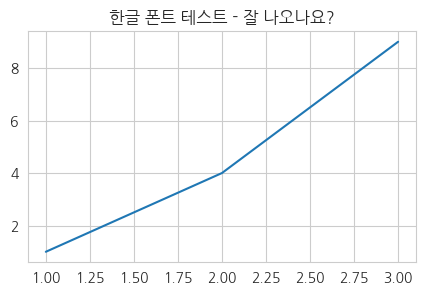

In [ ]:
plt.figure(figsize=(5, 3))
plt.title('한글 폰트 테스트 - 잘 나오나요?')
plt.plot([1, 2, 3], [1, 4, 9])
plt.show()

## 1. 데이터 로드 ##

In [ ]:
## 특수문자 포함된 칼럼
train = train.rename(columns = {'supply(kg)': 'supply', 'price(원/kg)': 'price'})

for df in (train, test):
  df['timestamp'] = pd.to_datetime(df['timestamp'])
  df['series'] = df['item'] + '_' + df['corporation'] + '_' + df['location']

print('train:', train.shape, train['timestamp'].min().date(), '~', train['timestamp'].max().date())
print('test:', test.shape, test['timestamp'].min().date(), '~', test['timestamp'].max().date())

train.head()

train: (59397, 8) 2019-01-01 ~ 2023-03-03
test: (1092, 6) 2023-03-04 ~ 2023-03-31


,ID,timestamp,item,corporation,location,supply,price,series
0,TG_A_J_20190101,2019-01-01,TG,A,J,0.0,0.0,TG_A_J
1,TG_A_J_20190102,2019-01-02,TG,A,J,0.0,0.0,TG_A_J
2,TG_A_J_20190103,2019-01-03,TG,A,J,60601.0,1728.0,TG_A_J
3,TG_A_J_20190104,2019-01-04,TG,A,J,25000.0,1408.0,TG_A_J
4,TG_A_J_20190105,2019-01-05,TG,A,J,32352.0,1250.0,TG_A_J


가격이 0이고 supply가 0인 데이터가 나타난다.

In [ ]:
## 데이터 구조 확인

print('train 시리즈 수: ', train['series'].nunique())
print('test 시리즈 수: ', test['series'].nunique())
print('\n test 시리즈 수: 일치: ', set(train['series'] == set(test['series'])))

per_series = train.groupby('series')['timestamp'].agg(['min', 'max', 'count'])
print('\n 시리즈별 행 수 분포: ', per_series['count'].describe())
print('\n 결측치: ', train.isna().sum())

train 시리즈 수:  39
test 시리즈 수:  39

 test 시리즈 수: 일치:  {False}

 시리즈별 행 수 분포:  count      39.0
mean     1523.0
std         0.0
min      1523.0
25%      1523.0
50%      1523.0
75%      1523.0
max      1523.0
Name: count, dtype: float64

 결측치:  ID             0
timestamp      0
item           0
corporation    0
location       0
supply         0
price          0
series         0
dtype: int64


In [ ]:
## 품목, 법인, 지역 조합

combo = train.drop_duplicates('series').pivot_table(index='item', columns=['location', 'corporation'], values = 'series', aggfunc = 'count')
combo = combo.fillna(0).astype(int)
combo

location     J                 S            
corporation  A  B  C  D  E  F  A  B  C  D  E
item                                        
BC           1  1  1  1  1  0  1  1  1  0  1
CB           1  0  0  1  1  1  1  0  0  0  0
CR           1  1  1  1  1  0  0  0  0  1  1
RD           1  0  0  1  1  1  1  0  1  1  1
TG           1  1  1  1  1  0  1  1  1  1  1

In [ ]:
## supply = 0과 price = 0의 관계

print(pd.crosstab(train['supply'] == 0, train['price'] == 0, rownames=['supply==0'], colnames=['price==0']))
print('가격 0인 비율: {:.1%}'.format((train['price'] == 0).mean()))

price==0   False  True 
supply==0              
False      23942      3
True           0  35452
가격 0인 비율: 59.7%


가격이 0이고 supply도 0인 데이터는 예외로 처리하고, 거래 없음으로 해석한다.

In [ ]:
## 공휴일 정의
holidays = pd.to_datetime([
    ## 2019
    '2019-01-01', '2019-02-04', '2019-02-05', '2019-02-06', '2019-03-01', '2019-05-05', '2019-05-06',
    '2019-05-12', '2019-06-06', '2019-08-15', '2019-09-12', '2019-09-13', '2019-09-14', '2019-10-03',
    '2019-10-09', '2019-12-25',
    ## 2020
    '2020-01-01', '2020-01-24', '2020-01-25', '2020-01-26', '2020-01-27', '2020-03-01', '2020-04-15',
    '2020-04-30', '2020-05-05', '2020-06-06', '2020-08-15', '2020-08-17', '2020-09-30', '2020-10-01',
    '2020-10-02', '2020-10-03', '2020-10-09', '2020-12-25',
    ## 2021
    '2021-01-01', '2021-02-11', '2021-02-12', '2021-02-13', '2021-03-01', '2021-05-05', '2021-05-19',
    '2021-06-06', '2021-08-15', '2021-08-16', '2021-09-20', '2021-09-21', '2021-09-22', '2021-10-03',
    '2021-10-04', '2021-10-09', '2021-10-11', '2021-12-25',
    ## 2022
    '2022-01-01', '2022-01-31', '2022-02-01', '2022-02-02', '2022-03-01', '2022-03-09', '2022-05-05',
    '2022-05-08', '2022-06-01', '2022-06-06', '2022-08-15', '2022-09-09', '2022-09-10', '2022-09-11',
    '2022-09-12', '2022-10-03', '2022-10-09', '2022-10-10', '2022-12-25',
    ## 2023
    '2023-01-01', '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24', '2023-03-01', '2023-05-05',
    '2023-05-27', '2023-05-29', '2023-06-06', '2023-08-15', '2023-09-28', '2023-09-29', '2023-09-30',
    '2023-10-02', '2023-10-03', '2023-10-09', '2023-12-25',
])

## 연휴 전 후의 효과를 보기 위해 설연휴와 추석연휴를 따로 보관
lunar_holidays = pd.to_datetime([
    '2019-02-04', '2019-02-05', '2019-02-06', '2019-09-12', '2019-09-13', '2019-09-14',
    '2020-01-24', '2020-01-25', '2020-01-26', '2020-01-27', '2020-09-30', '2020-10-01', '2020-10-02',
    '2021-02-11', '2021-02-12', '2021-02-13', '2021-09-20', '2021-09-21', '2021-09-22',
    '2022-01-31', '2022-02-01', '2022-02-02', '2022-09-09', '2022-09-10', '2022-09-11', '2022-09-12',
    '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24', '2023-09-28', '2023-09-29', '2023-09-30',
])

def calendar_features(df):
  d = df['timestamp']
  df['year'] = d.dt.year
  df['month'] = d.dt.month
  df['day'] = d.dt.day
  df['dayofweek'] = d.dt.dayofweek
  df['dayofyear'] = d.dt.dayofyear
  df['weekofyear'] = d.dt.isocalendar().week.astype(int)
  df['is_sunday'] = (df['dayofweek'] == 6).astype(int)
  df['is_holiday'] = d.isin(holidays).astype(int)
  df['is_offday'] = ((df['is_sunday'] == 1) | (df['is_holiday'] == 1)).astype(int)

  lunar = pd.Series(lunar_holidays)
  near = set()
  for k in [-2, -1, 1, 2]:
    near |= set(lunar + pd.Timedelta(days=k))
  df['near_lunar_holiday'] = (d.isin(near) & ~d.isin(lunar_holidays)).astype(int)

  df['doy_sin'] = np.sin(2 * np.pi * df['dayofyear'] / 365.25)
  df['doy_cos'] = np.cos(2 * np.pi * df['dayofyear'] / 365.25)
  return df

train = calendar_features(train)
test = calendar_features(test)
train['is_zero'] = (train['price'] == 0).astype(int)

## 2. EDA 및 전처리 ##

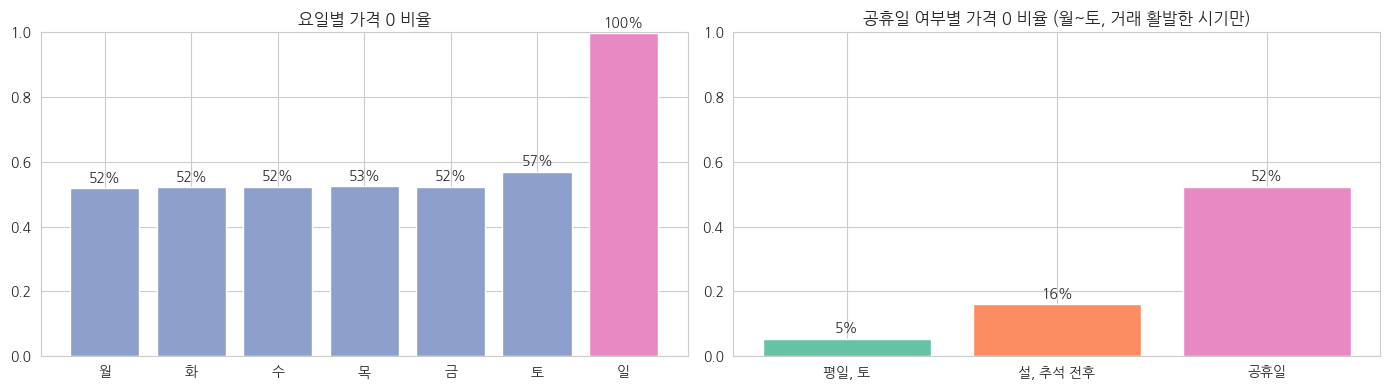

In [ ]:
## 요일별, 공휴일별 가격 0 비율

dow_label = ['월', '화', '수', '목', '금', '토', '일']
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

palette = sns.color_palette('Set2')
z_dow = train.groupby('dayofweek')['is_zero'].mean()
axes[0].bar(dow_label, z_dow.values, color=[palette[2]] * 6 + [palette[3]])
axes[0].set_title('요일별 가격 0 비율')
axes[0].set_ylim(0, 1)
for i, v in enumerate(z_dow.values):
  axes[0].text(i, v + 0.02, f'{v:.0%}', ha='center')

weekday = train[train['dayofweek']<6].copy()
active = (weekday[weekday['is_holiday'] == 0].groupby(['series', 'year', 'month'])['is_zero'].mean() < 0.3).rename('active')
weekday = weekday.join(active, on=['series', 'year', 'month'])
weekday = weekday[weekday['active'] == True]
weekday['구분'] = np.select([weekday['is_holiday'] == 1, weekday['near_lunar_holiday'] == 1], ['공휴일', '설, 추석 전후'], default='평일, 토')
z_hol = weekday.groupby('구분')['is_zero'].mean().reindex(['평일, 토', '설, 추석 전후', '공휴일'])
axes[1].bar(z_hol.index, z_hol.values, color=[palette[0], palette[1], palette[3]])
axes[1].set_title('공휴일 여부별 가격 0 비율 (월~토, 거래 활발한 시기만)')
axes[1].set_ylim(0, 1)
for i, v in enumerate(z_hol.values):
  axes[1].text(i, v + 0.02, f'{v:.0%}', ha='center')

plt.tight_layout()
plt.show()

요일별, 공휴일별 가격 0 비율을 알아본다.

- 공휴일 효과는 '비수기이기 때문에 0'과 섞이면 안 되니, 해당 월에 평소 거래가 활발했던 (평일 0비율 < 30%로 정의.) 시리즈 - 월만 사용한다.
- 일요일은 거의 100% 0. 거래가 활발한 시기 공휴일 0비율이 약 52%였으며, 이는 평일 약 5%의 10배에 달한다. 설, 추석 전후도 약 16%이다.

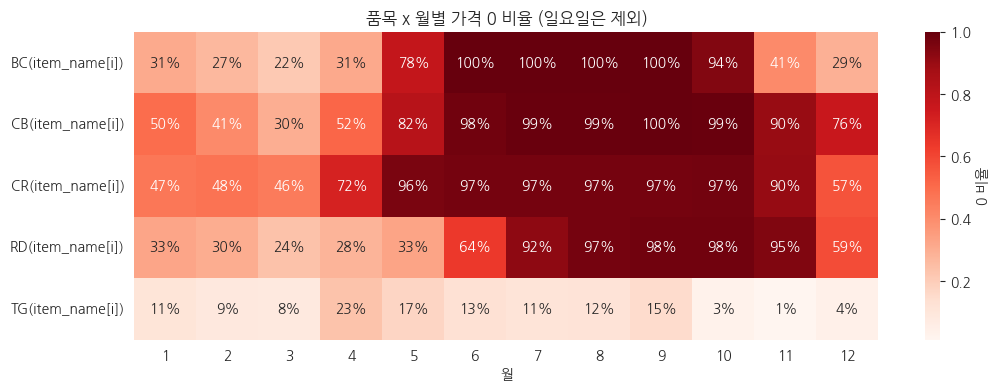

In [ ]:
## 품목 x 월별 가격 0 비율

monthly_zero_item = train[train['is_sunday'] == 0].pivot_table(index='item', columns='month', values='is_zero', aggfunc='mean')
monthly_zero_item.index = [f'{i}(item_name[i])' for i in monthly_zero_item.index]

plt.figure(figsize=(12, 4))
sns.heatmap(monthly_zero_item, annot=True, fmt='.0%', cmap='Reds', cbar_kws={'label': '0 비율'})
plt.title('품목 x 월별 가격 0 비율 (일요일은 제외)')
plt.xlabel('월')
plt.show()

품목 x 월별 가격 0 비율을 알아본다.

- 감귤은 거의 연중 거래된다.
- 브로콜리, 양배추, 당근, 무는 여름에서 가을까지 거의 거래가 없다.
- 예측 대상인 3월은 거의 모든 품목이 잘 거래된다.

In [ ]:
## 시리즈별 직전 28일의 0 비율 vs. 과거 3월 0 비율

last28days_hist = train[train['timestamp'] > train['timestamp'].max() - pd.Timedelta(days=28)]
march_hist = train[(train['month'] == 3) & (train['is_sunday'] == 0)]

zero_tbl = pd.DataFrame({
    '전체 기간 0 비율': train.groupby('series')['is_zero'].mean(),
    '직전 28일 0 비율': last28days_hist.groupby('series')['is_zero'].mean(),
    '3월 0 비율': march_hist.groupby('series')['is_zero'].mean(),
}).sort_values('직전 28일 0 비율')
zero_tbl.style.format('{:.0%}').background_gradient(cmap='Reds', vmin=0, vmax=1)

,전체 기간 0 비율,직전 28일 0 비율,3월 0 비율
series,,,
BC_A_J,53%,14%,0%
BC_A_S,58%,14%,2%
BC_B_J,63%,14%,4%
BC_C_J,63%,14%,15%
BC_E_J,53%,14%,0%
BC_D_J,56%,14%,0%
CB_F_J,62%,14%,1%
BC_E_S,62%,14%,2%
TG_B_J,23%,14%,7%


시리즈별 직전 28일 0 비율과 과거 3월 0 비율을 교차해 살펴본다.

- 직전 28일 0 비율 = 14%인 시리즈는 정상 거래 중이라고 볼 수 있다.
- CR_D_S, CR_E_S, BC_B_S, BC_C_S, RD_C_S 등은 직전 28일·과거 3월 모두 거의 0 → 0으로 예측된다.


In [ ]:
## 품목별 가격 분포

nz = train[train['price']>0].copy()

summary = nz.groupby('item')['price'].agg(['count', 'median', 'min', 'max', 'skew'])
summary['log_skew'] = nz.groupby('item')['price'].apply(lambda s: np.log1p(s).skew())
summary.index = [f'{i}({item_name[i]})' for i in summary.index]
summary.round(3)

,count,median,min,max,skew,log_skew
BC(브로콜리),4525,2518.0,205.0,8750.0,0.963,-0.400
CB(양배추),1620,619.0,162.0,2500.0,1.095,0.011
CR(당근),2082,1159.0,250.0,3882.0,1.466,0.548
RD(무),4040,468.0,50.0,5715.0,4.870,1.501
TG(감귤),11675,3847.0,551.0,20909.0,0.601,-0.227


품목별 가격 분포를 따로 살펴본다.

- 무의 중앙값은 468원인데 감귤은 3847원인 것을 보아 품목마다 가격 수준이 천차만별임을 알 수 있다.
- 무의 경우 왜도가 4.870으로 log변환 효과는 그만큼 크다. 감귤은 왜도가 작은 편이다.

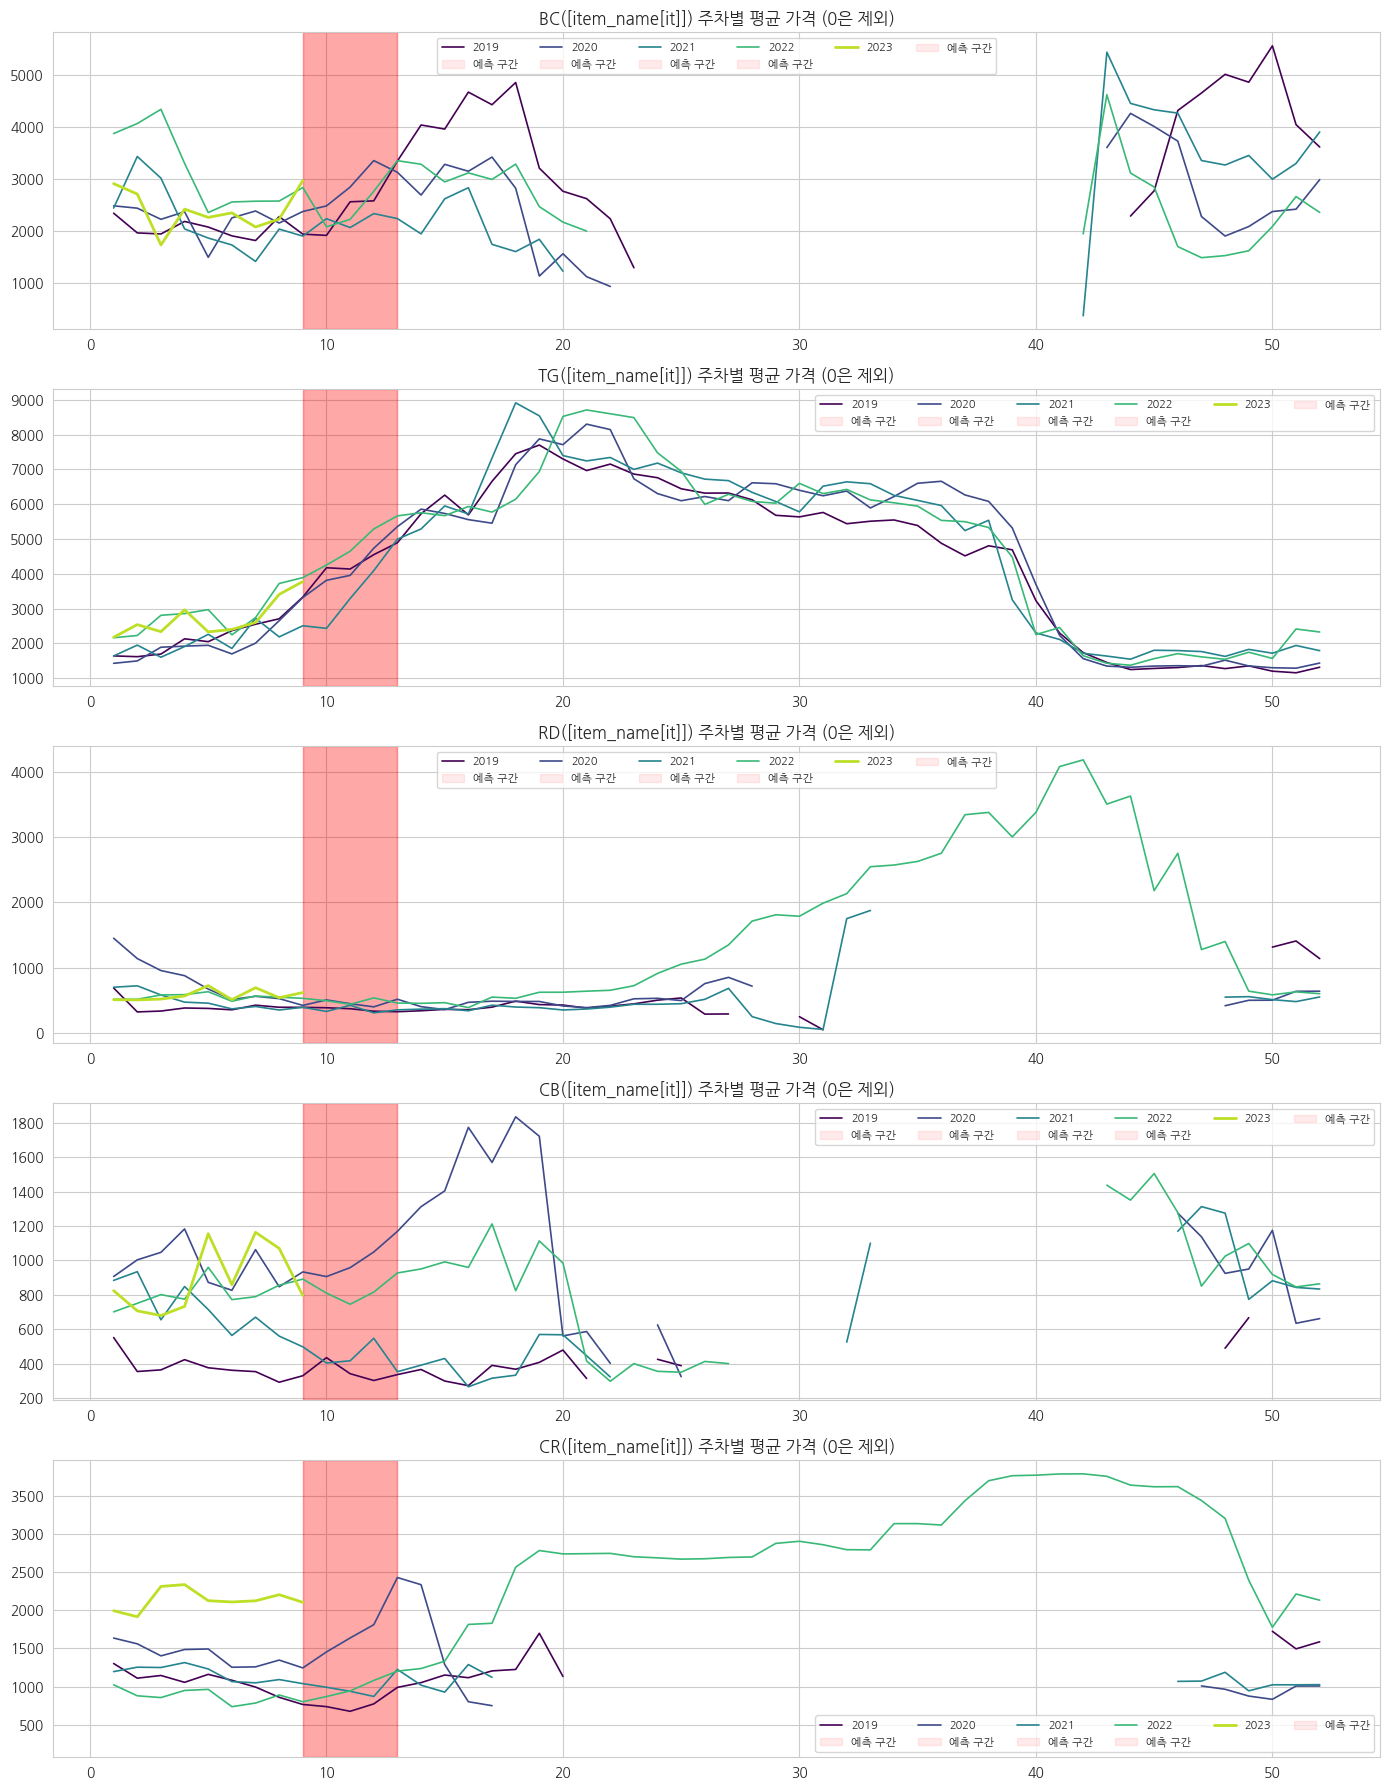

In [ ]:
## 시계열 패턴 보기

nz['week'] = nz['weekofyear'].clip(upper=52)
fig, axes = plt.subplots(5, 1, figsize=(14, 18))
for ax, it in zip(axes, items):
  w = nz[nz['item'] == it].pivot_table(index='week', columns='year', values='price', aggfunc='mean').reindex(range(1, 53))
  colors = plt.cm.viridis(np.linspace(0, 0.9, w.shape[1]))
  for c, yr in zip(colors, w.columns):
    ax.plot(w.index, w[yr], color=c, lw=2 if yr == 2023 else 1.2, label=str(yr))
    ax.axvspan(9, 13, color='red', alpha=0.08, label='예측 구간')
    ax.legend(ncol=6, fontsize=8)
    ax.set_title(f'{it}([item_name[it]]) 주차별 평균 가격 (0은 제외)')
plt.tight_layout()
plt.show()

연도별로 겹쳐보며 품목별로 시계열 패턴을 본다.

- 감귤: 매년 예측 구간인 3월에 가파르게 상승한다. 2월과 비교했을 때 3월 평균값이 약 1.5배 전후이다.
- 당근: 2022년 하반기부터 가격 수준이 과거의 약 2배에 달한다.
- 브로콜리, 양배추, 당근은 거래가 없는 여름과 가을 구간의 공백이 뚜렷하다.

In [ ]:
## 공급량과 가격의 관계

corr_tbl = nz.groupby('item').apply(lambda g: g['supply'].corr(g['price'], method='spearman')).rename('spearman')
corr_tbl.index = [f'{i}(item_name[i])' for i in corr_tbl.index]
print('0 포함 전체 상관: ', round(train[['supply', 'price']].corr().iloc[0, 1], 3))
print('\n 품목별 Spearman 상관 (0은 제외)')
print(corr_tbl.round(3))

0 포함 전체 상관:  -0.002

 품목별 Spearman 상관 (0은 제외)
BC(item_name[i])   -0.113
CB(item_name[i])   -0.292
CR(item_name[i])   -0.253
RD(item_name[i])   -0.266
TG(item_name[i])   -0.748
Name: spearman, dtype: float64


공급량과 가격 간의 관계를 살펴본다.

- 품목별로 봤을 때 모두 음의 상관을 보이며, 감귤이 가장 강한 음의 상관관계를 보인다.
- 단 test에는 supply가 없어서 과거 공급량으로만 사용 가능하다.

In [ ]:
## 이상치

def hampel_flag(s, window=15, k=4.0):
  med = s.rolling(window, center=True, min_periods=5).median()
  mad = (s-med).abs().rolling(window, center=True, min_periods=5).median()
  return (s-med).abs() > k * 1.4826 * mad.replace(0, np.nan)

nz = nz.sort_values(['series', 'timestamp'])
nz['outlier'] = nz.groupby('series', group_keys=False)['price'].apply(hampel_flag).fillna(False)
nz['supply_q'] = nz.groupby('item')['supply'].transform(lambda s: pd.qcut(s, 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5']))

print('이상치 추정: ', nz['outlier'].sum(), '건 / 0 제외 데이터', len(nz), '건')
print('\n 공급량 구간별 이상치 비율')
print(nz.groupby('supply_q', observed=True)['outlier'].mean().apply(lambda v: f'{v:.1%}'))

이상치 추정:  496 건 / 0 제외 데이터 23942 건

 공급량 구간별 이상치 비율
supply_q
Q1    4.2%
Q2    2.1%
Q3    1.5%
Q4    1.4%
Q5    1.1%
Name: outlier, dtype: object


이상치를 추정해 supply 구간별 이상치 비율을 구했다.

- 공급량이 적을 때 (Q1) 이상치 비율이 가장 높다. 즉, 소량 거래 시 가격이 튀는 현상을 보여준다.

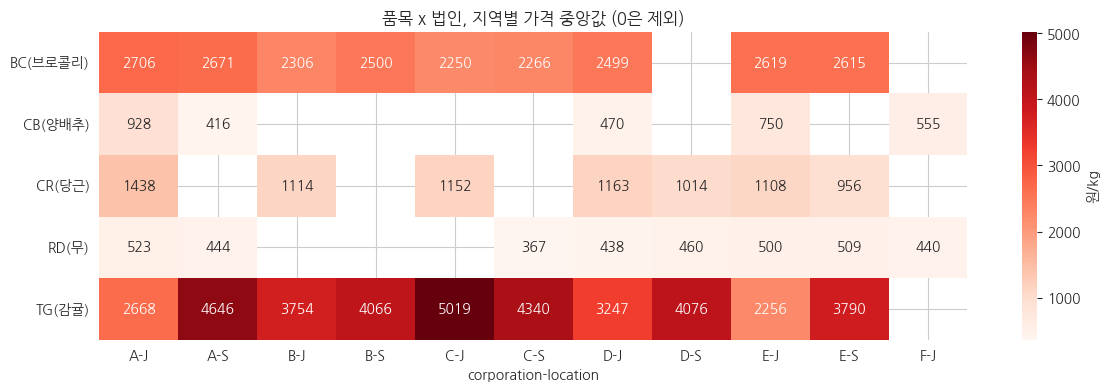

In [ ]:
## 법인, 지역 비교

pv = nz.pivot_table(index='item', columns=['corporation', 'location'], values='price', aggfunc='median')
pv.index = [f'{i}({item_name[i]})' for i in pv.index]
plt.figure(figsize=(14, 4))
sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '원/kg'})
plt.title('품목 x 법인, 지역별 가격 중앙값 (0은 제외)')
plt.show()

법인, 지역별로 품목을 비교해보았다.

- 같은 품목 안에서도 법인별, 지역별 가격 수준이 다른 것을 알 수 있다.

In [ ]:
## 전처리

HORIZON = 28   ## 예측 구간

full = pd.concat([train.assign(is_test=0), test.assign(is_test=1)], ignore_index=True)
full = full.sort_values(['series', 'timestamp']).reset_index(drop=True)

full['price_nz'] = full['price'].where(full['price'] > 0)
full['supply_nz'] = full['supply'].where(full['supply'] > 0)
g = full.groupby('series')

## 1) lag 피처: 28일 전, 35일 전(같은 요일), 364일 전(작년 같은 요일)
for lag in [28, 35, 42, 364]:
    full[f'price_lag{lag}'] = g['price'].shift(lag)
full['price_nz_lag364'] = g['price_nz'].shift(364)

## 2) rolling 피처: 28일 전 시점 기준 과거 7/14/28일 (0을 제외한 평균)
for w in [7, 14, 28]:
    full[f'price_nz_roll{w}_mean'] = g['price_nz'].transform(lambda s: s.shift(HORIZON).rolling(w, min_periods=1).mean())
full['price_nz_roll28_std'] = g['price_nz'].transform(lambda s: s.shift(HORIZON).rolling(28, min_periods=3).std())
full['supply_nz_roll28_mean'] = g['supply_nz'].transform(lambda s: s.shift(HORIZON).rolling(28, min_periods=1).mean())
full['zero_rate_roll28'] = g['price'].transform(lambda s: (s == 0).astype(float).shift(HORIZON).rolling(28, min_periods=1).mean())

## 3) 작년 같은 시기 ±7일 평균
full['price_nz_lastyear_win'] = g['price_nz'].transform(lambda s: s.shift(364 - 7).rolling(15, min_periods=1).mean())

for col in ['item', 'corporation', 'location', 'series']:
    full[f'{col}_code'] = full[col].astype('category').cat.codes

full = full.merge(nz[['ID', 'outlier']], on='ID', how='left')
full['outlier'] = full['outlier'].fillna(False).astype(int)

feature_cols = [c for c in full.columns if c not in
                ['ID', 'timestamp', 'item', 'corporation', 'location', 'series', 'supply', 'price',
                 'price_nz', 'supply_nz', 'is_zero', 'is_test',
                 'outlier']]
print('피처 수:', len(feature_cols))
print(feature_cols)

피처 수: 28
['year', 'month', 'day', 'dayofweek', 'dayofyear', 'weekofyear', 'is_sunday', 'is_holiday', 'is_offday', 'near_lunar_holiday', 'doy_sin', 'doy_cos', 'price_lag28', 'price_lag35', 'price_lag42', 'price_lag364', 'price_nz_lag364', 'price_nz_roll7_mean', 'price_nz_roll14_mean', 'price_nz_roll28_mean', 'price_nz_roll28_std', 'supply_nz_roll28_mean', 'zero_rate_roll28', 'price_nz_lastyear_win', 'item_code', 'corporation_code', 'location_code', 'series_code']


In [ ]:
## (test 첫날/마지막날 lag, rolling 값 train 기간 값으로 채워져있는지 확인하기 위한 셀)

chk = full[full['is_test'] == 1].groupby('timestamp')[['price_lag28', 'price_nz_roll28_mean', 'price_nz_lag364']].apply(lambda d: d.notna().mean())
print('test 날짜별 피처 채워진 비율')
print(chk.iloc[[0, -1]])

test 날짜별 피처 채워진 비율
            price_lag28  price_nz_roll28_mean  price_nz_lag364
timestamp                                                     
2023-03-04          1.0              0.871795         0.717949
2023-03-31          1.0              0.948718         0.641026


In [ ]:
## 결측 비율
full.loc[full['is_test'] == 0, feature_cols].isna().mean().sort_values(ascending=False).head(8).round(3)

,0
price_nz_lag364,0.695
price_nz_lastyear_win,0.547
price_nz_roll7_mean,0.454
price_nz_roll28_std,0.436
price_nz_roll14_mean,0.428
supply_nz_roll28_mean,0.392
price_nz_roll28_mean,0.392
price_lag364,0.239


In [ ]:
## 수출입 데이터 결합

trade_map = {'감귤': 'TG', '꽃양배추와 브로콜리(broccoli)': 'BC', '당근': 'CR', '양배추': 'CB', '방울다다기 양배추': 'CB'}
num_cols = ['수출 중량', '수출 금액', '수입 중량', '수입 금액', '무역수지']

trade_f = trade[trade['품목명'].isin(trade_map)].copy()
trade_f['item'] = trade_f['품목명'].map(trade_map)
trade_m = trade_f.groupby(['기간', 'item'], as_index=False)[num_cols].sum()
## 1개월 lag: 2월 데이터 → 3월 행에 붙임
trade_m['ym'] = pd.PeriodIndex(trade_m['기간'], freq='M') + 1
trade_m = trade_m.drop(columns='기간').rename(columns={c: f'trade_{c.replace(" ", "_")}_lag1m' for c in num_cols})
trade_cols = [c for c in trade_m.columns if c.startswith('trade_')]

full = full.drop(columns=[c for c in trade_cols if c in full.columns])
full['ym'] = full['timestamp'].dt.to_period('M')
full = full.merge(trade_m, on=['ym', 'item'], how='left').drop(columns='ym')

print('결합된 컬럼:', trade_cols)
print('\n품목별 결합 비율:') ## RD는 0이 정상임
print(full.groupby('item')[trade_cols[0]].apply(lambda s: s.notna().mean()).round(2))
print('\ntest 기간 결합 여부:', full.loc[full['is_test'] == 1, trade_cols[0]].notna().any())

결합된 컬럼: ['trade_수출_중량_lag1m', 'trade_수출_금액_lag1m', 'trade_수입_중량_lag1m', 'trade_수입_금액_lag1m', 'trade_무역수지_lag1m']

품목별 결합 비율:
item
BC    0.98
CB    0.98
CR    0.98
RD    0.00
TG    0.98
Name: trade_수출_중량_lag1m, dtype: float64

test 기간 결합 여부: True


In [ ]:
## Baseline RMSE

def rmse(y, p):
    return np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2))


cut = train['timestamp'].max() - pd.Timedelta(days=HORIZON)
tr, va = train[train['timestamp'] <= cut].copy(), train[train['timestamp'] > cut].copy()
recent = tr[tr['timestamp'] > cut - pd.Timedelta(days=HORIZON)]

## b1: 직전 28일 평균 (0 포함) — 단순 평균
b1 = recent.groupby('series')['price'].mean()
# b2: 직전 28일 0 제외 평균 + 일요일, 공휴일은 0
b2_level = recent[recent['price'] > 0].groupby('series')['price'].mean()
# b3: b2 + 직전 28일에 거의 거래가 없던 시리즈 (0비율 > 80%)는 전부 0
zero_recent = recent.groupby('series')['is_zero'].mean()
# b4: 요일별 0 제외 평균 + 휴무일 0 + 비활성 시리즈 0
b4_level = recent[recent['price'] > 0].groupby(['series', 'dayofweek'])['price'].mean()

va['b1_28일평균'] = va['series'].map(b1)
va['b2_0제외평균+휴무0'] = np.where(va['is_offday'] == 1, 0, va['series'].map(b2_level).fillna(0))
va['b3_+비활성시리즈0'] = np.where(va['series'].map(zero_recent) > 0.8, 0, va['b2_0제외평균+휴무0'])
va['b4_요일별평균'] = va.set_index(['series', 'dayofweek']).index.map(b4_level)
va['b4_요일별평균'] = va['b4_요일별평균'].fillna(va['series'].map(b2_level)).fillna(0)
va['b4_요일별평균'] = np.where((va['is_offday'] == 1) | (va['series'].map(zero_recent) > 0.8), 0, va['b4_요일별평균'])

res = {c: rmse(va['price'], va[c]) for c in ['b1_28일평균', 'b2_0제외평균+휴무0', 'b3_+비활성시리즈0', 'b4_요일별평균']}
res = pd.Series(res, name='검증 RMSE').round(1)
print(res)
print('\n품목별 RMSE (b3 기준):')
print(va.groupby('item').apply(lambda d: rmse(d['price'], d['b3_+비활성시리즈0'])).round(1))

b1_28일평균        1045.9
b2_0제외평균+휴무0     934.4
b3_+비활성시리즈0      931.5
b4_요일별평균         931.0
Name: 검증 RMSE, dtype: float64

품목별 RMSE (b3 기준):
item
BC     698.7
CB     464.7
CR     929.6
RD     294.1
TG    1470.6
dtype: float64


train의 마지막 28일 (2/4 ~ 3/3)을 검증 데이터셋으로 확인해 모델링 baseline RMSE를 계산했다.

## 3. Prophet 모델링
- 품목·법인·지역의 39개 시계열마다 Prophet 모델 1개씩 학습
- 마지막 28일 검증으로 EDA 기준선과 비교한 뒤, 전체 데이터로 2023년 3월 4일~31일 가격을 예측

### 3-1. Prophet 설치 및 모델 설정
시계열 데이터 특성을 고려한 Prophet 모델 구성 및 주요 파라미터 설정
- 품목·법인·지역별 39개 시계열에 각각 독립적인 모델을 적용함.
- 선형 추세와 연간·주간 계절성을 설정하여 가격의 시간적 변화와 반복적인 패턴을 포착하고자 하였으며, 추세 유연성(changepoint_prior_scale)은 기본값인 0.05로 설정함. 일요일 예측 가격은 별도의 후처리를 통해 0원으로 조정함.
- 예측 구간(3월 4일~31일)에는 공휴일이 없고 공급량은 테스트 구간에 값이 없어, 두 변수는 넣지 않음.

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('prophet') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'prophet'])

import logging
from prophet import Prophet
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)

# Prophet 모델 설정: 비교·튜닝 없이 한 번 고정
PROPHET_PARAMS = dict(
    growth='linear',
    seasonality_mode='additive',
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.05,
)
print('예측할 시계열 개수:', train['series'].nunique())

예측할 시계열 개수: 39


### 3-2. 시계열별 Prophet 모델 학습 및 예측
39개 시계열별 개별 모델 학습과 예측값 후처리
- 시계열마다 0원을 포함한 가격으로 학습하고, 음수 예측은 0으로, 일요일 예측은 0원으로 바꿈.
- 공휴일은 3·1절처럼 거래되는 날도 있어 0원으로 고정하지 않음.
- 예측값은 ID 기준으로 매칭함.

In [ ]:
def predict_prophet(history, target):
    result = target[['ID', 'series', 'timestamp']].copy().reset_index(drop=True)
    result['pred'] = np.nan

    if result['ID'].duplicated().any():
        raise ValueError('예측 대상에 중복 ID가 있습니다.')

    for series, rows in result.groupby('series', sort=False).groups.items():
        past = history.loc[history['series'].eq(series), ['timestamp', 'price']]
        past = past.rename(columns={'timestamp': 'ds', 'price': 'y'}).sort_values('ds')
        dates = result.loc[rows, 'timestamp']

        if len(past) < 30 or past['y'].nunique() < 2:
            level = float(past['y'].mean()) if len(past) else 0.0
            forecast = np.full(len(dates), level)
        else:
            model = Prophet(**PROPHET_PARAMS)
            model.fit(past)
            forecast = model.predict(pd.DataFrame({'ds': dates.to_numpy()}))['yhat'].to_numpy()

        result.loc[rows, 'pred'] = np.clip(forecast, 0, None)

    result.loc[result['timestamp'].dt.dayofweek.eq(6), 'pred'] = 0.0
    if result['pred'].isna().any() or not np.isfinite(result['pred']).all():
        raise ValueError('누락되거나 유한하지 않은 예측값이 있습니다.')
    return result

### 3-3. 마지막 28일 검증 및 Baseline 비교
검증 데이터셋을 활용한 RMSE 계산 및 모델 간 성능 비교
- 전체 학습 데이터 중 마지막 28일(2023.02.04.~2023.03.03.)을 검증 구간으로 설정함.
  - 2023년 2월 3일까지 학습하고 2023년 2월 4일~3월 3일을 예측
- 실제 가격과 예측 가격의 차이를 RMSE로 평가하고, EDA 기준선 4종(b1~b4)과 비교하여 Prophet 모델의 예측 성능을 분석함.

In [ ]:
valid_start = train['timestamp'].max() - pd.Timedelta(days=27)
history = train.loc[train['timestamp'] < valid_start].copy()
valid = train.loc[train['timestamp'] >= valid_start].copy()

valid_predictions = predict_prophet(history, valid)
valid_results = valid[['ID', 'timestamp', 'item', 'series', 'price']].merge(
    valid_predictions[['ID', 'pred']], on='ID', how='left', validate='one_to_one'
)
assert len(valid_results) == len(valid)
prophet_rmse = rmse(valid_results['price'], valid_results['pred'])
print('검증 기간:', valid_start.date(), '~', train['timestamp'].max().date())
print(f'Prophet RMSE: {prophet_rmse:,.2f}')
print('EDA Baseline과 비교 (동일 기간):')
print(pd.concat([res, pd.Series({'Prophet': round(prophet_rmse, 1)}, name='검증 RMSE')]))

print('\n품목별 Prophet RMSE:')
print(valid_results.groupby('item')[['price', 'pred']].apply(
    lambda d: rmse(d['price'], d['pred'])
).round(1))

검증 기간: 2023-02-04 ~ 2023-03-03
Prophet RMSE: 778.75
EDA Baseline과 비교 (동일 기간):
b1_28일평균        1045.9
b2_0제외평균+휴무0     934.4
b3_+비활성시리즈0      931.5
b4_요일별평균         931.0
Prophet          778.8
Name: 검증 RMSE, dtype: float64

품목별 Prophet RMSE:
item
BC     788.8
CB     491.3
CR     860.1
RD     436.6
TG    1007.1
dtype: float64


### 3-4. 품목별 Prophet 예측 성능 분석
품목별 Baseline 4(EDA 기준선 중 전체 RMSE가 가장 낮은 모델)와 Prophet의 RMSE를 산출하고 비교하여 예측 성능의 차이를 분석

품목별 Baseline 4와 Prophet RMSE 비교


,Baseline 4,Prophet
item,,
BC,703.75,788.81
CB,452.01,491.27
CR,932.97,860.07
RD,300.20,436.58
TG,1466.58,1007.09


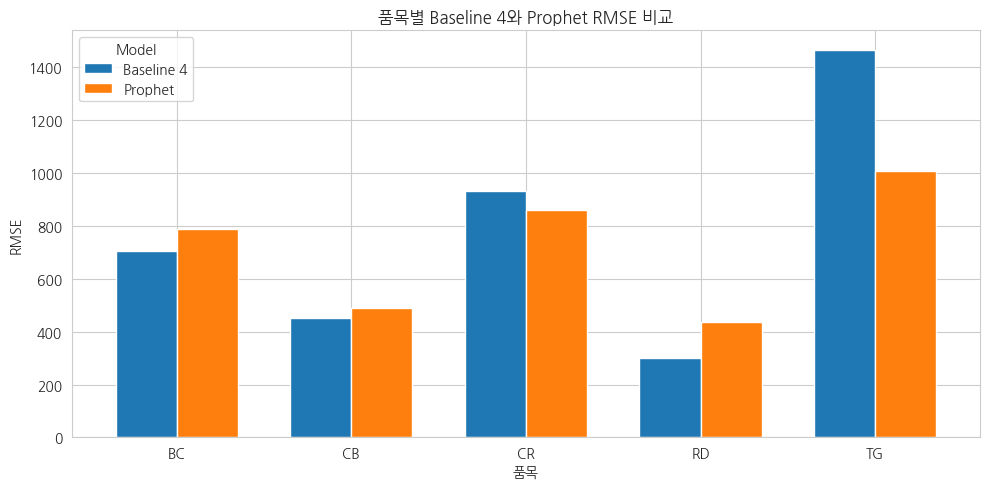

In [ ]:
# 품목별 Baseline 4 RMSE 계산
baseline_rmse = va.groupby('item').apply(
    lambda df: rmse(df['price'], df['b4_요일별평균'])
)

# 품목별 Prophet RMSE 계산
prophet_item_rmse = valid_results.groupby('item').apply(
    lambda df: rmse(df['price'], df['pred'])
)

# Baseline 4와 Prophet 비교표
rmse_comparison = pd.DataFrame({
    'Baseline 4': baseline_rmse,
    'Prophet': prophet_item_rmse
}).round(2)

print("품목별 Baseline 4와 Prophet RMSE 비교")
display(rmse_comparison)

# 품목별 RMSE 비교 시각화
ax = rmse_comparison.plot(
    kind='bar',
    figsize=(10, 5),
    width=0.7
)

plt.title('품목별 Baseline 4와 Prophet RMSE 비교')
plt.xlabel('품목')
plt.ylabel('RMSE')
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.tight_layout()
plt.show()


분석 결과, 감귤과 당근에서는 Prophet이 더 낮은 RMSE를 기록하였으나, 브로콜리·양배추·무에서는 Baseline 4가 더 우수한 성능을 보였다. 이를 통해 Prophet 모델의 예측 성능이 품목별로 다르게 나타남을 확인하였다.

### 3-5. 실제 가격과 예측 가격 비교
- 날짜별 평균 추이를 확인
- 검증 기간의 날짜별 실제 평균 가격과 Prophet 예측 평균 가격을 시각화

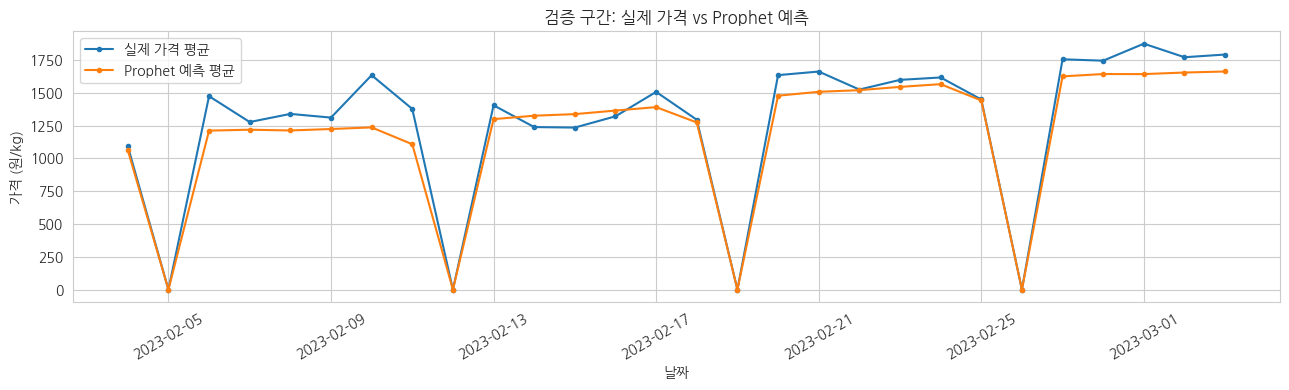

In [ ]:
daily = valid_results.groupby('timestamp')[['price', 'pred']].mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily['price'], marker='o', markersize=3, label='실제 가격 평균')
ax.plot(daily.index, daily['pred'], marker='o', markersize=3, label='Prophet 예측 평균')
ax.set(title='검증 구간: 실제 가격 vs Prophet 예측', xlabel='날짜', ylabel='가격 (원/kg)')
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

- 일요일마다 가격이 0원으로 떨어지는 패턴은 실제와 예측이 정확히 일치한다.
- 평일에는 예측 가격이 실제 가격보다 대체로 낮게 나타났다. 이는 거래가 없는 날의 가격을 0원으로 포함하여 학습한 영향일 가능성이 있으나, 정확한 원인을 확인하기 위해서는 추가적인 검증이 필요하다.

### 3-6. Prophet 예측 오차 분석
오차 분포 및 과대·과소 예측 경향 확인
- 실제 가격과 예측 가격의 차이를 계산하고, 오차 분포 및 예측 가격에 따른 오차를 시각화함.
- 이를 통해 예측 오차의 분포와 과대·과소 예측 경향을 분석하고, 가격 수준에 따른 모델의 예측 안정성을 검토하고자 함.

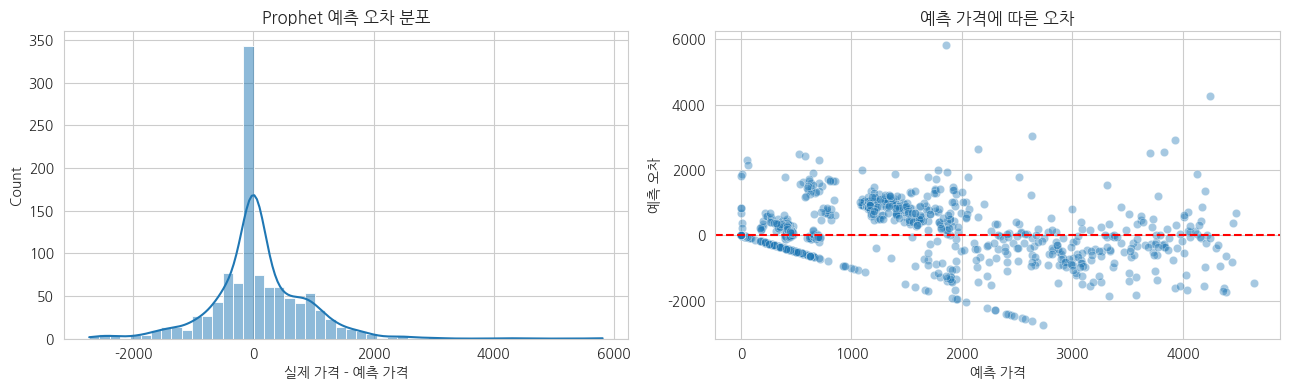

In [ ]:
# 예측 오차 계산
valid_results['error'] = (
    valid_results['price'] - valid_results['pred']
)

# 예측 오차 분포 시각화
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    valid_results['error'],
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Prophet 예측 오차 분포')
axes[0].set_xlabel('실제 가격 - 예측 가격')

sns.scatterplot(
    data=valid_results,
    x='pred',
    y='error',
    alpha=0.4,
    ax=axes[1]
)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('예측 가격에 따른 오차')
axes[1].set_xlabel('예측 가격')
axes[1].set_ylabel('예측 오차')

plt.tight_layout()
plt.show()


In [ ]:
# 예측 오차 요약 통계
error_summary = pd.Series({
    '평균 오차(ME)': valid_results['error'].mean(),
    '평균 절대 오차(MAE)': valid_results['error'].abs().mean(),
    'RMSE': rmse(valid_results['price'], valid_results['pred']),
    '과소 예측 비율(%)': (valid_results['error'] > 0).mean() * 100,
    '과대 예측 비율(%)': (valid_results['error'] < 0).mean() * 100
})

display(error_summary.round(2))


,0
평균 오차(ME),84.90
평균 절대 오차(MAE),507.70
RMSE,778.75
과소 예측 비율(%),40.84
과대 예측 비율(%),39.47


평균 오차가 양수이면 실제 가격보다 낮게 예측하는 경향이 있고, 음수이면 높게 예측하는 경향이 있다는 의미

- 평균 오차(ME)는 84.90원, 평균 절대 오차(MAE)는 507.70원으로 나타났다. 평균 오차가 양수이므로 전체적으로 실제 가격보다 낮게 예측하는 경향이 확인되었다. 과소 예측 비율은 40.84%, 과대 예측 비율은 39.47%로 나타났으며, 나머지는 실제값과 예측값이 일치한 경우이다.

### 3-7. 최종 모델 학습 및 예측 결과 파일 생성
- 전체 학습 데이터로 재학습해 3월 4일~31일을 예측하고, 결측·음수 검사 후 ID 기준으로 결합해 prophet_submission.csv(1,092행)로 저장함.

In [ ]:
final_predictions = predict_prophet(train, test)
answer_col = 'answer'
submission_final = submission[['ID']].merge(
    final_predictions[['ID', 'pred']], on='ID', how='left', validate='one_to_one'
).rename(columns={'pred': answer_col})

assert len(submission_final) == len(submission) == len(test) == 1092
assert submission_final['ID'].equals(submission['ID'])
assert submission_final[answer_col].notna().all()
assert np.isfinite(submission_final[answer_col]).all()
assert submission_final[answer_col].ge(0).all()

output_file = 'prophet_submission.csv'
submission_final.to_csv(output_file, index=False)
print(f'제출 파일 생성: {output_file} ({len(submission_final):,}행)')
display(submission_final.head())

제출 파일 생성: prophet_submission.csv (1,092행)


,ID,answer
0,TG_A_J_20230304,3704.632310
1,TG_A_J_20230305,0.000000
2,TG_A_J_20230306,4318.258617
3,TG_A_J_20230307,4239.496190
4,TG_A_J_20230308,4274.790425


### 3-8. 정리
- **검증 성능:** Prophet 모델의 검증 RMSE는 778.8로, EDA 기준선 중 가장 우수한 b4(931.0)보다 약 16.4% 낮게 나타났다. 이를 통해 해당 검증 구간에서 Prophet 모델이 기존 기준선보다 높은 예측 정확도를 보였음을 확인하였다.

- **품목별 성능 차이**: 감귤과 당근에서는 Prophet이 Baseline 4보다 우수한 성능을 보였으나, 브로콜리·양배추·무에서는 Baseline 4의 RMSE가 더 낮았다.

- **예측 오차**: 평균 오차는 84.90원으로, 전체적으로 실제 가격보다 낮게 예측하는 경향이 나타났다.
- **한계:** 2023년 2월 4일~3월 3일의 단일 28일 구간에서 검증하였으므로, 다른 기간에 대한 일반화 성능과 설정의 최적성을 확정하기 어렵다. 또한 Prophet은 거래 여부를 별도로 예측하지 않아, 거래가 없는 평일의 가격 예측에 한계가 있다.
